# 노출도 E 만들기 (사전기간 2019Q1~2021Q2)

> **이 노트북이 원본입니다.** 같은 폴더의 `06_노출도E_만들기.py`는 이 노트북에서 **자동 생성**됩니다. `.py`를 직접 고치지 말고 여기서 고친 뒤 `scripts/노트북에서_py_만들기.py`를 실행하세요.

| | |
|---|---|
| **알 수 있는 것** | 각 기업이 금리 인상 *전*에 "1년 안에 갚을 이자 붙는 빚"을 자산의 몇 %나 갖고 있었는지(**E**)를 어떻게 만드는지, 그리고 몇 곳에서 만들 수 있는지 |
| **입력** | `outputs/04_본수집/본수집_로그.csv`, `본수집_결과_기업별.csv`, `data/raw/DART_파일럿/fs/*.json` (저장된 재무제표 응답, 사전기간 13,078개) — **인증키 필요 없음** |
| **출력** | `outputs/06_노출도E/E_보고서별.csv`, `E_기업별.csv`, `E_요약.txt` |
| **걸리는 시간** | 약 2분 |
| **지위** | 규칙은 **에이전트 제안이고 팀 확인 전**입니다(`docs/A_결정_제안_근거표_11-05.md` D3·D4·D8). **ICR·영업이익은 읽지 않고, E와 ICR의 관계를 보지 않습니다.** |

## 0. E가 뭔가요? (30초 설명)

금리가 오르면 **빚을 새로 빌리거나 갚아야 하는 기업**이 이자 부담을 먼저 느낍니다. 1년 안에 갚아야 하는 빚(단기차입금, 1년 안에 만기가 오는 장기차입금·사채)이 많을수록 그렇습니다.

> **E = (1년 안에 갚을 이자 붙는 빚) ÷ 자산총계**   — 예) 자산 1,000억 원, 1년 안에 갚을 차입 150억 원이면 E = 0.15

이 노트북은 DART 재무제표 응답에서 이 숫자를 **어떻게 뽑는지**를 보여 줍니다. 핵심 아이디어는 하나입니다.

> 계정 *이름*("단기차입금")만으로는 회사마다 이름이 달라 놓치는 빚이 많아서, **재무상태표에서의 *위치*(유동부채 구간 안인가)로 "1년 안에 갚을 빚"을 찾는다.**

## 1. 준비: 무엇을 어디서 읽나

아래 셀은 필요한 도구를 불러오고, 공통 설정(`config`)을 읽어 옵니다. 노트북에서는 노트북이 있는 폴더를, `.py`로 돌릴 때는 파일이 있는 폴더를 기준으로 삼습니다.

In [1]:
"""사전기간(2019Q1~2021Q2) 노출도 E를 만든다. 규칙은 docs/A_결정_제안_근거표_11-05.md의 D3·D4·D8 (에이전트 제안, 팀 미확인).

규칙 (이 스크립트를 돌린 결과를 보고 바꾸지 않는다. 바꾸면 이유와 함께 변경 기록에 적는다)
  분자(D3) = 재무상태표 '유동부채' 구간(유동부채 머리행 ~ 비유동부채 머리행) 안에서, 이름에 '차입' 또는 '사채'가 있는 행의 금액 합.
             제외 단어: 리스, 할인발행차금, 상환할증금, 대손, 이자, 미지급, 매입, 채권, 차금.  (전환사채·신주인수권부사채·유동성사채 포함)
  분모       = 자산총계.     E_A = 분자 ÷ 분모 (분기마다)
  분기 상태(D4)
    DEBT  = 유동 구간에 위 차입·사채 행이 있음(합이 0일 수도 있음) → E 정의됨
    ZERO  = 차입·사채 행도 모호한 금융부채 행도 유동 구간에 없음 → E = 0 (확정)
    AMBIG = 차입·사채 행은 없고 '금융부채'(기타·단기·유동 금융부채 등, 파생·리스·손익인식 제외) 행만 있음 → 주 분석에서 E 정의 안 함
    NOHDR = 유동/비유동 머리행이 없음 → E 정의 안 함
  기업 E_pre(D8) = DEBT·ZERO 분기의 E_A 평균(주). AMBIG 분기를 0으로 넣은 값은 민감도 열(E_pre_A_amb0)로 따로 저장.
  보조(R1) E_B = 유동 구간 차입 ÷ (유동 + 비유동 구간 차입), 총차입금이 0이면 정의 안 함. 레버리지 = 총차입금 ÷ 자산총계.
  연결(CFS) 우선. 한 기업 안에서 연결·별도가 섞인 경우는 그대로 계산하고 '혼재' 표시만 한다.

ICR·영업이익은 읽지 않는다. E와 ICR의 관계를 보지 않는다.
실행: python -X utf8 06_노출도E_만들기.py  (저장된 파일만 읽음, 키 필요 없음)
저장: outputs/06_노출도E/E_보고서별.csv, E_기업별.csv, E_요약.txt
"""
import csv
import json
import re
import statistics
import sys
from collections import Counter, defaultdict
from pathlib import Path

try:
    HERE = Path(__file__).resolve().parent      # .py로 실행할 때
except NameError:
    HERE = Path.cwd()                           # 노트북에서 실행할 때(노트북이 있는 폴더)
sys.path.insert(0, str(HERE.parent / "01_파일럿"))
import config  # noqa: E402

if hasattr(sys.stdout, "reconfigure"):          # 노트북의 출력 창에는 이 함수가 없다
    sys.stdout.reconfigure(encoding="utf-8")

## 2. 무엇을 '차입'으로 볼까 (이름 규칙)

**위치 방식**으로 구간을 정한 뒤, 그 구간 안의 계정 중 *이름*으로 "이자 붙는 빚"을 골라냅니다.

| 구분 | 규칙(정규식) | 예 |
|---|---|---|
| **차입으로 본다** (`DEBT`) | 이름에 `차입`, `사채`, `장기부채`, `당좌차월` | 단기차입금, 유동성장기차입금, 유동성사채, 유동성전환사채, **유동성장기부채**, 당좌차월 |
| **뺀다** (`EXCL`) | `리스`, `할인발행차금`, `상환할증금`, `대손`, `이자`, `미지급`, `매입`, `채권`, `차금` | 유동리스부채, 사채할인발행차금, 미지급이자, 매입채무 |
| **애매하다** (`AMBIG`) | `금융부채` (단 `파생·리스·손익·매매` 제외) | 기타유동금융부채, 단기금융부채 → 차입인지 이름으로는 모름 |

> **이력 (보정 1).** 처음에는 `DEBT`에 `차입|사채`만 있어서 **"유동성장기부채"를 빠뜨렸습니다.** 사전 고정 문서와 파일럿 규칙에는 처음부터 있던 이름이었습니다. 검산에서 유동 구간 1,514개 보고서에 이 이름이 있는 것을 발견해 추가했고, 이 때문에 E=0으로 잘못 분류되던 보고서 55개가 바로잡혔습니다. (5장 `docs/A_팀전달_전체보고서_11-05.html` 오류 일지 #3)

In [2]:
LOG = config.BASE / "outputs" / "04_본수집" / "본수집_로그.csv"
RESULT = config.BASE / "outputs" / "04_본수집" / "본수집_결과_기업별.csv"
OUTDIR = config.BASE / "outputs" / "06_노출도E"
FS_DIR = config.RAW / "fs"
REP_ORDER = {"Q1": 0, "H1": 1, "Q3": 2, "FY": 3}
# 2026-11-05 보정: '유동성장기부채'(사전 고정 5절·config.ACCOUNT_PATTERNS에 원래 있던 이름)와 '당좌차월'을 추가.
# 1차 실행(07_E_검산 점검 3·4)에서 이 이름이 유동 구간 1,514개 보고서에 있는데 규칙에서 빠져 E가 과소 계산된 것을 발견. E와 ICR의 관계는 보지 않은 상태에서의 수정.
DEBT = re.compile(r"차입|사채|장기부채|당좌차월")
EXCL = re.compile(r"리스|할인발행차금|상환할증금|대손|이자|미지급|매입|채권|차금")
AMBIG = re.compile(r"금융부채")
AMBIG_EXCL = re.compile(r"파생|리스|손익|매매")

## 3. 재무상태표에서 '1년 안에 갚을 구간' 찾기 (위치 방식)

재무상태표의 부채 부분은 이런 순서로 적혀 있습니다.

```
유동부채            ← 머리행: 여기부터 "1년 안에 갚을 부채" 구간
   매입채무
   단기차입금        ← 구간 안: 단기 차입으로 센다 (E의 분자)
   유동성장기차입금   ← 구간 안: 1년 안에 만기가 오는 장기차입도 센다
비유동부채           ← 머리행: 여기부터 "1년 넘게 갚을 부채" 구간
   장기차입금        ← 구간 밖: E에는 안 넣고, 총차입금 계산에만 쓴다
부채총계             ← 부채 끝
```

`sections()`가 머리행(유동부채·비유동부채·부채총계)을 찾아 **각 행이 어느 구간에 있는지** 표시합니다. 이 방법은 저장된 응답 34,964개 전체에서 **이름과 99.95%, 표준 계정코드와 99.99% 일치**했습니다(`07_계정확보/05_위치분류_검증`).

아래 셀에는 도우미 함수 네 개가 있습니다: `norm`(공백 제거), `to_num`(숫자로 바꾸기), `is_pre`(사전기간인지), `sections`(구간 표시).

In [3]:
def norm(s):
    return re.sub(r"\s+", "", s or "")


def to_num(v):
    try:
        return float(str(v).replace(",", "").strip())
    except ValueError:
        return None


def is_pre(y, rep):
    return (2019, 0) <= (y, REP_ORDER[rep]) <= (2021, 1)


def sections(bs):
    hdr = []
    for i, r in enumerate(bs):
        nm, aid = norm(r["account_nm"]), r.get("account_id", "")
        if nm == "유동부채" or aid == "ifrs-full_CurrentLiabilities":
            hdr.append((i, "C"))
        elif nm == "비유동부채" or aid == "ifrs-full_NoncurrentLiabilities":
            hdr.append((i, "N"))
        elif nm == "부채총계" or aid == "ifrs-full_Liabilities":
            hdr.append((i, "T"))
    has = any(t == "C" for _, t in hdr) and any(t == "N" for _, t in hdr)
    sec, cur, hi = {}, "O", 0
    for i in range(len(bs)):
        while hi < len(hdr) and hdr[hi][0] <= i:
            cur = {"C": "C", "N": "N", "T": "O"}[hdr[hi][1]]
            hi += 1
        sec[i] = cur
    return sec, has

## 4. 합계 행과 세부 행을 두 번 세지 않기 (보정 2)

일부 회사는 재무상태표에 **합계 행과 그 세부 행을 같이** 적습니다. 예를 들어:

```
단기차입금        117,609백만원   ← 합계 행
   단기차입금      112,385백만원   ← 세부 행
   유동성장기차입금  5,224백만원   ← 세부 행   (112,385 + 5,224 = 117,609)
```

셋을 다 더하면 **같은 빚을 두 번 세게** 됩니다. `dedup()`이 두 가지 규칙으로 합계 행을 뺍니다.

1. 어떤 행의 금액이 **바로 뒤 연속 1~5개 행의 합과 같으면** 그 행은 합계 행이다.
2. 이름이 같은 연속 두 행에서 앞 행에는 표준 계정코드가 있고 뒤 행에는 없으면(액면·장부 이중 표기) 뒤 행을 뺀다.

> **이력 (보정 2).** 검산에서 유동차입 합이 유동부채보다 큰 27건을 발견하고 만든 규칙입니다. 13개 회사 38개 보고서에 적용되어 17개 보고서의 E가 바뀌었고, 전체 분포는 거의 그대로였습니다.

In [4]:
def dedup(rows):
    """같은 차입이 '합계 행'과 '세부 행'으로 함께 적힌 경우의 이중 계산을 막는다. (2026-11-05 보정 2: 07_E_검산 점검 2에서 발견)
    규칙 1) 어떤 행의 금액이 바로 뒤 연속 1~5개 차입 행의 합과 같으면(±1원 또는 0.001%) 그 행은 합계 행이므로 뺀다.
    규칙 2) 남은 행 중 이름이 같은 연속 두 행에서 앞 행에 표준 계정코드가 있고 뒤 행에 없으면(표준계정코드 미사용) 뒤 행을 뺀다(액면·장부 이중 표기).
    rows: [(이름, 금액, account_id)] → (남은 행, 뺀 행 수)"""
    drop = set()
    n = len(rows)
    for i in range(n):
        amt = rows[i][1]
        if amt <= 0:
            continue
        s = 0.0
        for k in range(i + 1, min(n, i + 6)):
            s += rows[k][1]
            if abs(s - amt) <= max(1.0, amt * 1e-5):
                drop.add(i)
                break
    kept = [r for i, r in enumerate(rows) if i not in drop]
    drop2 = set()
    for i in range(len(kept) - 1):
        a, b = kept[i], kept[i + 1]
        if a[0] == b[0] and not a[2].startswith("-") and b[2].startswith("-"):
            drop2.add(i + 1)
    kept = [r for i, r in enumerate(kept) if i not in drop2]
    return kept, len(drop) + len(drop2)

## 5. 보고서 한 개에서 분자와 상태 만들기

`one_report()`는 재무제표 응답 **하나**를 받아 유동 구간·비유동 구간의 차입 합과 **상태**를 돌려줍니다.

| 상태 | 뜻 | E는? |
|---|---|---|
| `DEBT` | 유동 구간에 차입·사채 행이 있음(합이 0일 수도 있음) | **정의됨** (분자 ÷ 자산) |
| `ZERO` | 차입 행도 애매한 금융부채 행도 유동 구간에 **전혀 없음** | **E = 0 (확정)** |
| `AMBIG` | 차입 행은 없고 "기타·단기 금융부채"만 있어 **차입인지 모름** | 주 분석에서 **정의 안 함** |
| `NOHDR` | 유동·비유동 머리행이 없어 구간을 못 나눔 | 정의 안 함 |

"0 확정"과 "애매"를 구분하는 것이 중요합니다. **없다고 확인된 것**과 **있는지 모르는 것**을 섞으면, 차입이 없는 기업(E가 가장 낮은 비교 집단)이 통째로 사라지거나 잘못 0이 되기 때문입니다.

In [5]:
def one_report(d):
    bs = sorted([x for x in d if x.get("sj_div") == "BS"], key=lambda x: int(x["ord"]))
    sec, has = sections(bs)
    assets = next((to_num(x["thstrm_amount"]) for x in bs if norm(x["account_nm"]) == "자산총계"), None)
    out = {"assets": assets, "num_C": 0.0, "num_N": 0.0, "n_debt_rows_C": 0, "n_ambig_rows_C": 0}
    if not has:
        out["state"] = "NOHDR"
        return out
    rows_c, rows_n = [], []
    for i, x in enumerate(bs):
        nm = norm(x["account_nm"])
        amt = to_num(x["thstrm_amount"])
        aid = x.get("account_id", "")
        if sec[i] == "C":
            if DEBT.search(nm) and not EXCL.search(nm):
                rows_c.append((nm, amt or 0.0, aid))
            elif AMBIG.search(nm) and not AMBIG_EXCL.search(nm) and not DEBT.search(nm):
                out["n_ambig_rows_C"] += 1
        elif sec[i] == "N":
            if DEBT.search(nm) and not EXCL.search(nm):
                rows_n.append((nm, amt or 0.0, aid))
    rows_c, dc = dedup(rows_c)
    rows_n, dn = dedup(rows_n)
    out["n_debt_rows_C"] = len(rows_c)
    out["num_C"] = sum(a for _, a, _ in rows_c)
    out["num_N"] = sum(a for _, a, _ in rows_n)
    out["n_dedup"] = dc + dn
    out["state"] = "DEBT" if out["n_debt_rows_C"] else ("AMBIG" if out["n_ambig_rows_C"] else "ZERO")
    return out


def q(v, p):
    v = sorted(v)
    return v[min(len(v) - 1, int(round(p * (len(v) - 1))))]

## 6. 직접 보기: 실제 보고서 하나로 따라가기

위 규칙이 실제 재무상태표에서 어떻게 작동하는지 **합계·세부 행이 같이 있는 실제 사례**(회사 코드 `00149239`, 2019 사업보고서)로 따라가 봅니다. 연결 재무제표가 있으면 연결을, 없으면 별도를 씁니다.

In [6]:
import pandas as pd

firm, year, rep = "00149239", 2019, "FY"
for fs in ("CFS", "OFS"):                       # 수집 규칙과 같다: 연결(CFS)을 먼저 보고, 자료가 없으면 별도(OFS)
    응답 = json.loads((FS_DIR / f"{firm}_{year}_{config.REPORTS[rep]}_{fs}.json").read_text(encoding="utf-8"))
    if 응답.get("status") == "000":
        break
print(f"사용한 재무제표: {'연결' if fs == 'CFS' else '별도'}({fs})")
d = 응답["list"]
bs = sorted([x for x in d if x.get("sj_div") == "BS"], key=lambda x: int(x["ord"]))
sec, has = sections(bs)

# 유동부채 구간 안에서 이름에 차입·사채가 들어간 행들
rows = [(norm(x["account_nm"]), to_num(x["thstrm_amount"]) or 0.0, x.get("account_id", "")) for i, x in enumerate(bs)
        if sec[i] == "C" and DEBT.search(norm(x["account_nm"]))]
표 = pd.DataFrame([{"계정": nm, "금액(원)": f"{amt:,.0f}", "표준 계정코드": aid[:32]} for nm, amt, aid in rows])
표

사용한 재무제표: 별도(OFS)


,계정,금액(원),표준 계정코드
0,단기차입금,"117,608,730,260",ifrs-full_ShorttermBorrowings
1,단기차입금,"112,384,570,256",-표준계정코드 미사용-
2,유동성장기차입금,"5,224,160,004",-표준계정코드 미사용-
3,유동성전환사채,"5,431,823,318",dart_CurrentPortionOfConvertible
4,유동성전환사채,"6,000,000,000",-표준계정코드 미사용-
5,사채상환할증금,"465,798,000",-표준계정코드 미사용-
6,사채할인발행차금,"48,737,362",-표준계정코드 미사용-


In [7]:
# 제외 단어가 들어간 행(할인발행차금, 상환할증금 등)을 뺀 뒤, 합계·세부 행 중복을 제거해 보기
후보 = [r for r in rows if not EXCL.search(r[0])]
남은, 뺀수 = dedup(후보)
print(f"중복 제거 전: 행 {len(후보)}개, 합 = {sum(a for _, a, _ in 후보):,.0f}원")
print(f"중복 제거 후: 행 {len(남은)}개, 합 = {sum(a for _, a, _ in 남은):,.0f}원  (뺀 행 {뺀수}개)")

o = one_report(d)
print(f"\none_report 결과: 상태={o['state']}, 유동 구간 차입 합={o['num_C']:,.0f}원, 자산총계={o['assets']:,.0f}원")
print(f"→ 이 보고서의 E = {o['num_C'] / o['assets']:.3f}   (중복 제거 전 값이었다면 {sum(a for _, a, _ in 후보) / o['assets']:.3f})")

중복 제거 전: 행 5개, 합 = 246,649,283,838원
중복 제거 후: 행 3개, 합 = 123,040,553,578원  (뺀 행 2개)

one_report 결과: 상태=DEBT, 유동 구간 차입 합=123,040,553,578원, 자산총계=289,296,274,077원
→ 이 보고서의 E = 0.425   (중복 제거 전 값이었다면 0.853)


## 7. 모든 보고서에 적용해 기업별 E 만들기 (`main`)

`main()`은 사전기간(2019Q1~2021Q2, 기업당 최대 10개 보고서) **13,078개**를 하나씩 읽어 다음을 합니다.

1. 보고서마다 `E_A` = 유동 구간 차입 ÷ 자산 (`DEBT`이면 계산, `ZERO`면 0, 그 밖은 정의 안 함)
2. 보조로 `E_B` = 단기 비중(유동 차입 ÷ 총차입), `레버리지` = 총차입 ÷ 자산
3. **기업별**로 정의된 분기의 평균을 `E_pre_A`로 저장. 애매 분기를 0으로 넣은 값(`E_pre_A_amb0`)은 민감도용으로 따로 저장
4. 기업을 `차입있음 / 0확정 / 혼합 / 정의불가`로 분류하고, 요약(`E_요약.txt`)을 만듭니다.

연결 재무제표(CFS)를 먼저 쓰고, 한 기업 안에서 연결·별도가 섞인 경우는 그대로 계산하되 `연결별도_혼재`로만 표시합니다.

In [8]:
def main():
    firms = {r["corp_code"]: r for r in csv.DictReader(open(RESULT, encoding="utf-8-sig"))}
    chosen = {}
    for r in csv.DictReader(open(LOG, encoding="utf-8-sig")):
        if r["status"] == "000" and is_pre(int(r["year"]), r["report"]):
            k = (r["corp_code"], int(r["year"]), r["report"])
            if k not in chosen or r["fs_div"] == "CFS":
                chosen[k] = r["fs_div"]
    OUTDIR.mkdir(parents=True, exist_ok=True)
    rep_rows = []
    for i, ((c, y, rep), fs) in enumerate(sorted(chosen.items()), 1):
        d = json.loads((FS_DIR / f"{c}_{y}_{config.REPORTS[rep]}_{fs}.json").read_text(encoding="utf-8"))["list"]
        o = one_report(d)
        st, a = o["state"], o["assets"]
        valid_assets = a is not None and a > 0
        e_a = None
        if st in ("DEBT", "ZERO") and valid_assets:
            e_a = (o["num_C"] / a) if st == "DEBT" else 0.0
        tot = o["num_C"] + o["num_N"]
        e_b = (o["num_C"] / tot) if (st in ("DEBT", "ZERO") and tot > 0) else None
        lev = (tot / a) if (st != "NOHDR" and valid_assets) else None
        rep_rows.append({"corp_code": c, "year": y, "report": rep, "fs_div": fs, "상태": st,
                         "자산총계": a, "유동차입합": o["num_C"], "비유동차입합": o["num_N"],
                         "유동차입행수": o["n_debt_rows_C"], "중복제거행수": o.get("n_dedup", 0), "모호금융부채행수": o["n_ambig_rows_C"],
                         "E_A": e_a, "E_B": e_b, "레버리지": lev, "자산이상": (not valid_assets)})
        if i % 4000 == 0:
            print(f"  {i:,}개 읽음")
    cols = list(rep_rows[0].keys())
    with open(OUTDIR / "E_보고서별.csv", "w", encoding="utf-8-sig", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=cols)
        w.writeheader()
        w.writerows(rep_rows)

    by = defaultdict(list)
    for r in rep_rows:
        by[r["corp_code"]].append(r)
    frows = []
    for c, f in firms.items():
        rs = by.get(c, [])
        df = [r for r in rs if r["E_A"] is not None]
        st = Counter(r["상태"] for r in rs)
        amb0 = [r["E_A"] if r["E_A"] is not None else (0.0 if r["상태"] == "AMBIG" and not r["자산이상"] else None) for r in rs]
        amb0 = [x for x in amb0 if x is not None]
        eb = [r["E_B"] for r in rs if r["E_B"] is not None]
        lev = [r["레버리지"] for r in rs if r["레버리지"] is not None]
        n_def = len(df)
        if n_def == 0:
            cls = "정의불가"
        elif all(r["상태"] == "DEBT" for r in df):
            cls = "차입있음(정의된 전 분기)"
        elif all(r["상태"] == "ZERO" for r in df):
            cls = "0확정(정의된 전 분기)"
        else:
            cls = "혼합"
        frows.append({"corp_code": c, "회사명": f["회사명"], "현재_법인구분": f["현재_법인구분"], "업종2": f["업종코드"][:2],
                      "연결별도_혼재": f["연결별도_혼재"], "사전기간_보고서수": len(rs), "E정의된_분기수": n_def,
                      "상태_DEBT": st["DEBT"], "상태_ZERO": st["ZERO"], "상태_AMBIG": st["AMBIG"], "상태_NOHDR": st["NOHDR"],
                      "E_pre_A": statistics.mean([r["E_A"] for r in df]) if df else "",
                      "E_pre_A_amb0(민감도)": statistics.mean(amb0) if amb0 else "",
                      "E_pre_B(보조)": statistics.mean(eb) if eb else "",
                      "레버리지_pre": statistics.mean(lev) if lev else "",
                      "기업분류": cls, "모호분기_있음": st["AMBIG"] > 0})
    with open(OUTDIR / "E_기업별.csv", "w", encoding="utf-8-sig", newline="") as fh:
        w = csv.DictWriter(fh, fieldnames=list(frows[0].keys()))
        w.writeheader()
        w.writerows(frows)

    L = []
    N = len(rep_rows)
    L.append(f"사전기간 보고서 {N:,}개(기업 {len(frows):,}곳)")
    c = Counter(r["상태"] for r in rep_rows)
    L.append("분기 상태: " + ", ".join(f"{k} {v:,}({v/N:.1%})" for k, v in c.most_common()))
    L.append(f"자산총계가 없거나 0 이하: {sum(1 for r in rep_rows if r['자산이상']):,}건")
    over = sum(1 for r in rep_rows if r["E_A"] is not None and r["E_A"] > 1)
    L.append(f"E_A > 1(유동 차입이 자산보다 큼): {over:,}건")
    L.append("")
    L.append("[A8 목록 1] 사전기간 E를 만들 수 있는 기업")
    nd = Counter(r["E정의된_분기수"] for r in frows)
    L.append("  E가 정의된 분기 수별 기업 수: " + ", ".join(f"{k}개:{nd[k]}" for k in sorted(nd)))
    L.append(f"  E가 정의된 분기가 1개 이상인 기업 {sum(1 for r in frows if r['E정의된_분기수']>=1):,}곳 / 정의불가 {nd[0]}곳")
    cl = Counter((r["기업분류"], r["모호분기_있음"]) for r in frows)
    L.append("  기업 분류(모호 분기 여부):")
    for (k, a), v in sorted(cl.items()):
        L.append(f"    {k} / 모호분기 {'있음' if a else '없음'}: {v:,}곳")
    L.append("")
    L.append("[분포] 기업별 E_pre_A (정의된 기업만)")
    vals = [r["E_pre_A"] for r in frows if r["E_pre_A"] != ""]
    L.append(f"  n={len(vals):,} | 평균={statistics.mean(vals):.3f} | 10%={q(vals,.1):.3f} 25%={q(vals,.25):.3f} 중앙값={statistics.median(vals):.3f} 75%={q(vals,.75):.3f} 90%={q(vals,.9):.3f} 최대={max(vals):.3f}")
    L.append(f"  E_pre_A = 0인 기업: {sum(1 for v in vals if v == 0):,}곳 ({sum(1 for v in vals if v==0)/len(vals):.1%})")
    L.append("  법인구분별(정의된 기업): ")
    g = defaultdict(list)
    for r in frows:
        if r["E_pre_A"] != "":
            g[r["현재_법인구분"]].append(r["E_pre_A"])
    for k, v in sorted(g.items()):
        L.append(f"    {k}: n={len(v)} 중앙값={statistics.median(v):.3f} 평균={statistics.mean(v):.3f}")
    L.append("")
    L.append("[A8 목록 3] E를 못 만드는/애매한 기업이 몰리는가")
    tot_g = Counter(r["현재_법인구분"] for r in frows)
    und_g = Counter(r["현재_법인구분"] for r in frows if r["E정의된_분기수"] == 0)
    amb_g = Counter(r["현재_법인구분"] for r in frows if r["모호분기_있음"])
    for k in sorted(tot_g):
        L.append(f"  {k}: {tot_g[k]}곳 | 정의불가 {und_g[k]}({und_g[k]/tot_g[k]:.1%}) | 모호 분기 있음 {amb_g[k]}({amb_g[k]/tot_g[k]:.1%})")
    ind_t = Counter(r["업종2"] for r in frows)
    ind_a = Counter(r["업종2"] for r in frows if r["모호분기_있음"] or r["E정의된_분기수"] == 0)
    L.append("  업종(앞 2자리)별 '모호 분기 있음 또는 정의불가' 비율 (기업 10곳 이상 업종):")
    for k in sorted(ind_t):
        if ind_t[k] >= 10:
            L.append(f"    {k}: {ind_a[k]}/{ind_t[k]} ({ind_a[k]/ind_t[k]:.0%})")
    mx = Counter(r["연결별도_혼재"] for r in frows)
    L.append("")
    L.append(f"연결·별도 혼재 기업 {mx['True']}곳(사전기간 분기 상태가 섞여 있을 수 있음). 주 분석은 혼재 기업 제외(D6)이므로 아래 수는 참고:")
    main_f = [r for r in frows if r["연결별도_혼재"] != "True"]
    L.append(f"  혼재 제외 후 {len(main_f):,}곳 중 E 정의된 기업 {sum(1 for r in main_f if r['E정의된_분기수']>=1):,}곳, 모호 분기 있음 {sum(1 for r in main_f if r['모호분기_있음']):,}곳")
    ntxt = "\n".join(L)
    print(ntxt)
    (OUTDIR / "E_요약.txt").write_text(ntxt, encoding="utf-8")
    print("저장:", OUTDIR)

### (.py에만 들어가는 부분)

노트북에서는 `__name__`이 항상 `"__main__"`이라서 아래 코드를 일반 셀로 두면 노트북을 열 때마다 `main()`이 저절로 실행됩니다. 그래서 **실행하지 않는 이 설명 셀**에 두고, 변환 스크립트가 `.py`에만 넣습니다.

```python
if __name__ == "__main__":
    main()
```

## 8. 실행

아래 셀이 `main()`을 실행해 결과 파일 세 개를 **다시 만듭니다**(약 2분, 같은 입력이면 같은 결과).

In [9]:
main()

  4,000개 읽음


  8,000개 읽음


  12,000개 읽음


사전기간 보고서 13,078개(기업 1,321곳)
분기 상태: DEBT 11,183(85.5%), AMBIG 1,001(7.7%), ZERO 835(6.4%), NOHDR 59(0.5%)
자산총계가 없거나 0 이하: 9건
E_A > 1(유동 차입이 자산보다 큼): 22건

[A8 목록 1] 사전기간 E를 만들 수 있는 기업
  E가 정의된 분기 수별 기업 수: 0개:64, 1개:9, 2개:7, 3개:6, 4개:7, 5개:10, 6개:12, 7개:44, 8개:39, 9개:30, 10개:1093
  E가 정의된 분기가 1개 이상인 기업 1,257곳 / 정의불가 64곳
  기업 분류(모호 분기 여부):
    0확정(정의된 전 분기) / 모호분기 없음: 38곳
    0확정(정의된 전 분기) / 모호분기 있음: 13곳
    정의불가 / 모호분기 없음: 2곳
    정의불가 / 모호분기 있음: 62곳
    차입있음(정의된 전 분기) / 모호분기 없음: 1,033곳
    차입있음(정의된 전 분기) / 모호분기 있음: 71곳
    혼합 / 모호분기 없음: 91곳
    혼합 / 모호분기 있음: 11곳

[분포] 기업별 E_pre_A (정의된 기업만)
  n=1,257 | 평균=0.153 | 10%=0.004 25%=0.045 중앙값=0.134 75%=0.234 90%=0.316 최대=1.351
  E_pre_A = 0인 기업: 70곳 (5.6%)
  법인구분별(정의된 기업): 
    E: n=92 중앙값=0.225 평균=0.243
    K: n=746 중앙값=0.124 평균=0.142
    Y: n=419 중앙값=0.135 평균=0.153

[A8 목록 3] E를 못 만드는/애매한 기업이 몰리는가
  E: 100곳 | 정의불가 8(8.0%) | 모호 분기 있음 15(15.0%)
  K: 774곳 | 정의불가 28(3.6%) | 모호 분기 있음 106(13.7%)
  Y: 447곳 | 정의불가 28(6.3%) | 모호 분기 있음 36(8.1%)
  업종(앞 2

## 9. 저장된 결과 보기

방금 만든(또는 이전에 만든) `E_기업별.csv`에서 기업 몇 곳과 E의 분포를 봅니다.

,corp_code,회사명,현재_법인구분,E정의된_분기수,E_pre_A,레버리지_pre,기업분류
0,00164618,현대사료,K,10,0.280167,0.300694,차입있음(정의된 전 분기)
1,01046708,바디텍메드,K,10,0.072453,0.114086,차입있음(정의된 전 분기)
2,00493431,자안바이오,E,10,0.206584,0.239983,차입있음(정의된 전 분기)
3,00608839,에이루트,K,10,0.133270,0.152653,차입있음(정의된 전 분기)
4,00869272,서전기전,K,10,0.044359,0.044359,차입있음(정의된 전 분기)
5,00148522,퍼스텍,Y,10,0.037432,0.066781,차입있음(정의된 전 분기)
6,00155638,피에스텍,K,10,0.028183,0.069833,차입있음(정의된 전 분기)
7,00158219,시그네틱스,K,10,0.070004,0.099625,차입있음(정의된 전 분기)


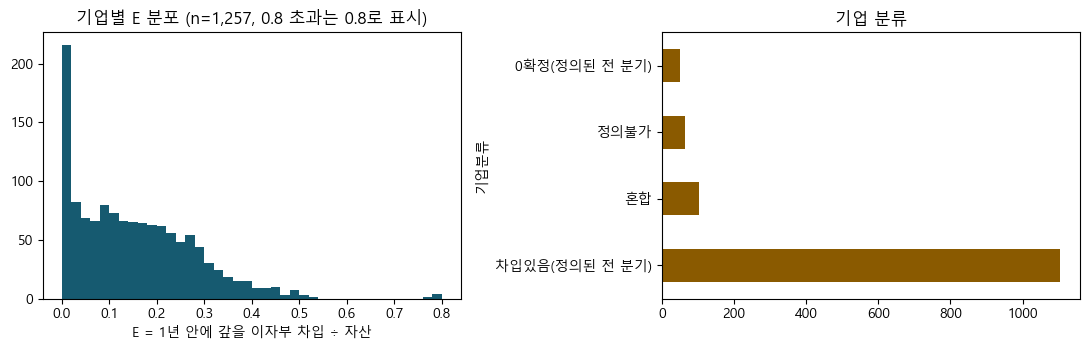

In [10]:
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

E = pd.read_csv(OUTDIR / "E_기업별.csv", dtype={"corp_code": str})
display(E[["corp_code", "회사명", "현재_법인구분", "E정의된_분기수", "E_pre_A", "레버리지_pre", "기업분류"]].head(8))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vals = pd.to_numeric(E["E_pre_A"], errors="coerce").dropna()
ax[0].hist(vals.clip(upper=0.8), bins=40, color="#165a70")
ax[0].set_title(f"기업별 E 분포 (n={len(vals):,}, 0.8 초과는 0.8로 표시)")
ax[0].set_xlabel("E = 1년 안에 갚을 이자부 차입 ÷ 자산")
E["기업분류"].value_counts().plot.barh(ax=ax[1], color="#8a5a00")
ax[1].set_title("기업 분류")
plt.tight_layout()
plt.show()

## 10. 읽는 법 · 주의 · 이력

**읽는 법**
- `E_pre_A`는 "긴축 전 평균적으로 자산의 몇 %를 1년 안에 갚을 차입으로 갖고 있었나"입니다. 중앙값은 약 0.13(자산의 13%)입니다.
- `E정의된_분기수`가 10이면 사전기간 10개 분기가 모두 정의된 기업입니다. 분석 표본에는 **8개 이상**인 기업만 씁니다(임의 기준).
- `기업분류`: `차입있음` 정의된 모든 분기에 차입 행이 있음 / `0확정` 정의된 모든 분기가 확정적으로 0 / `혼합` / `정의불가`(E를 만들 수 있는 분기가 하나도 없음).

**주의**
- **애매(`AMBIG`) 분기는 E에서 빠집니다.** 그런데 애매 분기는 E가 낮은 기업에 몰려 있어서, 이를 빼면 낮은 E 쪽이 조금 덜 대표됩니다. 그래서 애매를 0으로 둔 `E_pre_A_amb0`을 민감도로 함께 저장합니다.
- `E_A`가 1을 넘는 보고서 22개(6개 회사)는 오류가 아니라 **자본잠식**(자본총계가 음수) 회사의 실제 값입니다.
- 위치 방식도 완벽하지 않습니다. 보정 후에도 유동차입 합이 유동부채보다 큰 보고서 14건이 남아 있고(구조 확인 필요), `유동성전환상환우선주부채` 같은 이름은 차입이 아니라고 보고 뺐습니다.
- E는 **변동금리·만기 정보가 없는 대리변수**라서 "금리 민감도"가 아니라 "단기 차입·차환 위험"으로 해석해야 합니다.

**이력** (두 보정 모두 E와 ICR의 관계를 보기 전에 한 수정)

| 단계 | 문제 | E 정의 기업 | E 중앙값 |
|---|---|---|---|
| 1차 | `유동성장기부채` 누락 | 1,254곳 | 0.129 |
| 보정 1 | 이름 규칙에 추가 | 1,257곳 | 0.134 |
| 보정 2 | 합계·세부 행 이중 계산 제거 | 1,257곳 | 0.134 |

**다음 단계:** `07_E_검산`(이 결과를 검산) → `08_분석/01_패널_만들기`(E를 분기 패널에 붙임)